# UTS Pemodelan dan Simulasi
## Pemodelan dan Simulasi Sistem Dinamik Perubahan Tutupan Hutan di Indonesia Berdasarkan Laju Kehilangan dan Skenario Pemulihan Hutan

### 1. Data Understanding dan Validasi Dataset

**Metode:** Dynamic System Modelling (System Dynamics)

**Wilayah:** Indonesia

**Periode:** 2001–2024

**Dataset:** Tree Cover Loss

**Tujuan:**
1. Memahami struktur dataset.
2. Memeriksa kelengkapan data.
3. Memastikan periode pengamatan.
4. Mengidentifikasi missing values dan duplikasi.
5. Memeriksa konsistensi nilai kehilangan tutupan hutan.
6. Menghasilkan statistik deskriptif dan visualisasi awal.

In [1]:
# ==========================================
# CELL 2 - IMPORT LIBRARY
# ==========================================

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Library berhasil diimpor.")
print("Pandas version :", pd.__version__)
print("NumPy version  :", np.__version__)
print("Matplotlib     :", plt.matplotlib.__version__)

Library berhasil diimpor.
Pandas version : 3.1.0
NumPy version  : 2.5.4
Matplotlib     : 3.11.2


In [ ]:
# ==========================================
# CELL 3 - LOAD DATASET
# ==========================================

DATA_PATH = "../data/raw/tree_cover_loss.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {os.path.abspath(DATA_PATH)}"
    )

df_original = pd.read_csv(DATA_PATH)

print("=" * 60)
print("DATASET BERHASIL DIMUAT")
print("=" * 60)

print("Lokasi file :", os.path.abspath(DATA_PATH))
print("Jumlah baris:", len(df_original))
print("Jumlah kolom:", len(df_original.columns))
print("Ukuran data :", df_original.shape)

print("\nNama seluruh kolom:")
for i, col in enumerate(df_original.columns, start=1):
    print(f"{i}. {col}")

print("\nLima data pertama:")
display(df_original.head().to_string(index=False))

In [21]:
# ==========================================
# CELL 4 - STRUKTUR DATASET
# ==========================================

print("=" * 60)
print("INFORMASI DATASET")
print("=" * 60)

df_original.info()

print("\nTipe data setiap kolom:")
for col in df_original.columns:
    print(f"{col:<30} : {df_original[col].dtype}")

print("\nJumlah nilai unik setiap kolom:")
display(
    df_original.nunique(dropna=False)
    .rename("Jumlah Nilai Unik")
    .to_frame()
)

INFORMASI DATASET
<class 'pandas.DataFrame'>
RangeIndex: 5016 entries, 0 to 5015
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Entity  5016 non-null   str    
 1   Code    5016 non-null   str    
 2   Year    5016 non-null   int64  
 3   Total   5016 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 219.0 KB

Tipe data setiap kolom:
Entity                         : str
Code                           : str
Year                           : int64
Total                          : float64

Jumlah nilai unik setiap kolom:


,Jumlah Nilai Unik
Entity,209
Code,209
Year,24
Total,4715


In [4]:
# ==========================================
# CELL 5 - SAMPEL DATA
# ==========================================

print("10 BARIS PERTAMA")
display(df_original.head(10))

print("\n10 BARIS TERAKHIR")
display(df_original.tail(10))

print("\nSAMPEL ACAK")
display(df_original.sample(
    min(10, len(df_original)),
    random_state=42
))

10 BARIS PERTAMA


,Entity,Code,Year,Total
0,Afghanistan,AFG,2001,70.87
1,Afghanistan,AFG,2002,152.58
2,Afghanistan,AFG,2003,221.00
3,Afghanistan,AFG,2004,183.54
4,Afghanistan,AFG,2005,211.50
5,Afghanistan,AFG,2006,136.91
6,Afghanistan,AFG,2007,229.17
7,Afghanistan,AFG,2008,97.81
8,Afghanistan,AFG,2009,55.47
9,Afghanistan,AFG,2010,78.03



10 BARIS TERAKHIR


,Entity,Code,Year,Total
5006,Zimbabwe,ZWE,2015,"12,219.77"
5007,Zimbabwe,ZWE,2016,"10,903.84"
5008,Zimbabwe,ZWE,2017,"25,847.25"
5009,Zimbabwe,ZWE,2018,"6,530.54"
5010,Zimbabwe,ZWE,2019,"11,497.80"
5011,Zimbabwe,ZWE,2020,"6,190.65"
5012,Zimbabwe,ZWE,2021,"8,975.68"
5013,Zimbabwe,ZWE,2022,"8,205.03"
5014,Zimbabwe,ZWE,2023,"5,655.91"
5015,Zimbabwe,ZWE,2024,"5,821.21"



SAMPEL ACAK


,Entity,Code,Year,Total
2588,Lithuania,LTU,2021,"22,600.20"
3199,New Caledonia,NCL,2008,440.10
2986,Mongolia,MNG,2011,"3,320.65"
4515,Thailand,THA,2004,"91,100.94"
1666,French Guiana,GUF,2011,"2,304.10"
1170,Cuba,CUB,2019,"7,433.92"
2957,Moldova,MDA,2006,149.84
2242,Jamaica,JAM,2011,"2,365.02"
1543,Ethiopia,ETH,2008,"23,504.42"
2029,Honduras,HND,2014,"57,419.35"


In [5]:
# ==========================================
# CELL 6 - VALIDASI NAMA KOLOM
# ==========================================

print("=" * 60)
print("VALIDASI KOLOM DATASET")
print("=" * 60)

expected_columns = ["Entity", "Code", "Year"]

for col in expected_columns:
    if col not in df_original.columns:
        raise ValueError(f"Kolom wajib tidak ditemukan: {col}")

print("Kolom identitas ditemukan:")
print(expected_columns)

value_columns = [
    col for col in df_original.columns
    if col not in expected_columns
]

print("\nKolom selain identitas:")
print(value_columns)

if len(value_columns) != 1:
    print("\nPERHATIAN: Jumlah kolom indikator tidak sesuai ekspektasi.")
    print("Perlu pemeriksaan struktur dataset lebih lanjut.")

else:
    indicator_column = value_columns[0]

    print("\nKolom indikator yang ditemukan:", indicator_column)

    if indicator_column != "Total":
        print(
            f"Kolom indikator bernama '{indicator_column}', "
            "bukan 'Total'."
        )
        print("Belum dilakukan perubahan nama.")

VALIDASI KOLOM DATASET
Kolom identitas ditemukan:
['Entity', 'Code', 'Year']

Kolom selain identitas:
['Total']

Kolom indikator yang ditemukan: Total


In [6]:
# ==========================================
# CELL 7 - MISSING VALUES
# ==========================================

missing_count = df_original.isnull().sum()

missing_percentage = (
    df_original.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    "Kolom": df_original.columns,
    "Missing Values": missing_count.values,
    "Persentase (%)": missing_percentage.values
})

print("=" * 60)
print("LAPORAN MISSING VALUES")
print("=" * 60)

display(missing_report.to_string(index=False))

total_missing = int(missing_count.sum())

print("\nTotal seluruh missing values:", total_missing)
print(
    "Status:",
    "Tidak ditemukan missing values."
    if total_missing == 0
    else "Ditemukan missing values, perlu pemeriksaan."
)

LAPORAN MISSING VALUES


' Kolom  Missing Values  Persentase (%)\nEntity               0            0.00\n  Code               0            0.00\n  Year               0            0.00\n Total               0            0.00'


Total seluruh missing values: 0
Status: Tidak ditemukan missing values.


In [7]:
# ==========================================
# CELL 8 - DUPLICATE DATA
# ==========================================

duplicate_count = df_original.duplicated().sum()

print("=" * 60)
print("PEMERIKSAAN DUPLIKASI")
print("=" * 60)

print("Jumlah baris duplikat:", duplicate_count)

if duplicate_count > 0:
    print("\nContoh data duplikat:")
    display(
        df_original[
            df_original.duplicated(keep=False)
        ].sort_values(by=["Entity", "Year"]).head(20)
    )
else:
    print("Tidak ditemukan baris duplikat.")

PEMERIKSAAN DUPLIKASI
Jumlah baris duplikat: 0
Tidak ditemukan baris duplikat.


In [8]:
# ==========================================
# CELL 9 - ENTITY DAN COUNTRY CODE
# ==========================================

print("=" * 60)
print("DAFTAR ENTITAS")
print("=" * 60)

entities = (
    df_original.groupby(["Entity", "Code"], dropna=False)
    .size()
    .reset_index(name="Jumlah Baris")
    .sort_values("Entity")
)

print("Jumlah kombinasi Entity dan Code:", len(entities))

display(entities.head(30).to_string(index=False))

print("\nPencarian entitas Indonesia:")

indonesia_data = df_original[
    (df_original["Entity"].astype(str).str.strip().str.lower() == "indonesia") |
    (df_original["Code"].astype(str).str.strip().str.upper() == "IDN")
]

if indonesia_data.empty:
    print("Indonesia belum ditemukan dalam dataset.")
else:
    print("Indonesia ditemukan.")
    print("Jumlah baris:", len(indonesia_data))
    display(indonesia_data.head(10))

DAFTAR ENTITAS
Jumlah kombinasi Entity dan Code: 209


'                         Entity     Code  Jumlah Baris\n                    Afghanistan      AFG            24\n                         Africa OWID_AFR            24\n                  Aland Islands      ALA            24\n                        Albania      ALB            24\n                        Algeria      DZA            24\n                        Andorra      AND            24\n                         Angola      AGO            24\n                       Anguilla      AIA            24\n            Antigua and Barbuda      ATG            24\n                      Argentina      ARG            24\n                        Armenia      ARM            24\n                          Aruba      ABW            24\n                           Asia OWID_ASI            24\n                      Australia      AUS            24\n                        Austria      AUT            24\n                     Azerbaijan      AZE            24\n                        Bahamas      BHS       


Pencarian entitas Indonesia:
Indonesia ditemukan.
Jumlah baris: 24


,Entity,Code,Year,Total
2088,Indonesia,IDN,2001,"741,476.90"
2089,Indonesia,IDN,2002,"852,752.50"
2090,Indonesia,IDN,2003,"543,327.44"
2091,Indonesia,IDN,2004,"1,286,451.90"
2092,Indonesia,IDN,2005,"1,180,546.60"
2093,Indonesia,IDN,2006,"1,430,826.90"
2094,Indonesia,IDN,2007,"1,385,629.00"
2095,Indonesia,IDN,2008,"1,394,440.10"
2096,Indonesia,IDN,2009,"1,941,935.80"
2097,Indonesia,IDN,2010,"1,276,621.40"


In [9]:
# ==========================================
# CELL 10 - FILTER INDONESIA
# ==========================================

df_id = df_original[
    (df_original["Code"].astype(str).str.strip().str.upper() == "IDN") |
    (df_original["Entity"].astype(str).str.strip().str.lower() == "indonesia")
].copy()

df_id = df_id.drop_duplicates()

print("=" * 60)
print("DATASET KHUSUS INDONESIA")
print("=" * 60)

print("Jumlah baris:", len(df_id))
print("Jumlah kolom:", len(df_id.columns))

if not df_id.empty:
    display(df_id.head(10))
else:
    print("Data Indonesia tidak ditemukan.")

DATASET KHUSUS INDONESIA
Jumlah baris: 24
Jumlah kolom: 4


,Entity,Code,Year,Total
2088,Indonesia,IDN,2001,"741,476.90"
2089,Indonesia,IDN,2002,"852,752.50"
2090,Indonesia,IDN,2003,"543,327.44"
2091,Indonesia,IDN,2004,"1,286,451.90"
2092,Indonesia,IDN,2005,"1,180,546.60"
2093,Indonesia,IDN,2006,"1,430,826.90"
2094,Indonesia,IDN,2007,"1,385,629.00"
2095,Indonesia,IDN,2008,"1,394,440.10"
2096,Indonesia,IDN,2009,"1,941,935.80"
2097,Indonesia,IDN,2010,"1,276,621.40"


In [10]:
# ==========================================
# CELL 11 - VALIDASI PERIODE
# ==========================================

if df_id.empty:
    raise ValueError("Dataset Indonesia kosong.")

df_id["Year"] = pd.to_numeric(
    df_id["Year"],
    errors="coerce"
)

print("=" * 60)
print("INFORMASI PERIODE DATA")
print("=" * 60)

print("Tahun paling awal :", df_id["Year"].min())
print("Tahun paling akhir:", df_id["Year"].max())

print(
    "Jumlah tahun unik :",
    df_id["Year"].nunique()
)

print("\nDaftar tahun tersedia:")
print(sorted(df_id["Year"].dropna().unique().astype(int)))

INFORMASI PERIODE DATA
Tahun paling awal : 2001
Tahun paling akhir: 2024
Jumlah tahun unik : 24

Daftar tahun tersedia:
[np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [11]:
# ==========================================
# CELL 12 - CEK TAHUN HILANG
# ==========================================

expected_years = list(range(2001, 2025))

available_years = sorted(
    df_id["Year"].dropna().astype(int).unique()
)

missing_years = sorted(
    set(expected_years) - set(available_years)
)

extra_years = sorted(
    set(available_years) - set(expected_years)
)

print("=" * 60)
print("VALIDASI TAHUN 2001-2024")
print("=" * 60)

print("Jumlah tahun yang diharapkan:", len(expected_years))
print("Jumlah tahun tersedia:", len(available_years))

print("\nTahun yang tersedia:")
print(available_years)

print("\nTahun yang hilang:")
print(missing_years if missing_years else "Tidak ada")

print("\nTahun di luar periode penelitian:")
print(extra_years if extra_years else "Tidak ada")

print(
    "\nStatus:",
    "LENGKAP"
    if not missing_years and not extra_years
    else "PERLU PEMERIKSAAN"
)

VALIDASI TAHUN 2001-2024
Jumlah tahun yang diharapkan: 24
Jumlah tahun tersedia: 24

Tahun yang tersedia:
[np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Tahun yang hilang:
Tidak ada

Tahun di luar periode penelitian:
Tidak ada

Status: LENGKAP


In [12]:
# ==========================================
# CELL 13 - FILTER 2001-2024
# ==========================================

df_id_period = df_id[
    df_id["Year"].between(2001, 2024)
].copy()

df_id_period = df_id_period.sort_values("Year")

print("=" * 60)
print("DATA PENELITIAN 2001-2024")
print("=" * 60)

print("Jumlah baris:", len(df_id_period))
print("Periode:", int(df_id_period["Year"].min()), "-", int(df_id_period["Year"].max()))

display(df_id_period.to_string(index=False))

DATA PENELITIAN 2001-2024
Jumlah baris: 24
Periode: 2001 - 2024


'   Entity Code  Year        Total\nIndonesia  IDN  2001   741,476.90\nIndonesia  IDN  2002   852,752.50\nIndonesia  IDN  2003   543,327.44\nIndonesia  IDN  2004 1,286,451.90\nIndonesia  IDN  2005 1,180,546.60\nIndonesia  IDN  2006 1,430,826.90\nIndonesia  IDN  2007 1,385,629.00\nIndonesia  IDN  2008 1,394,440.10\nIndonesia  IDN  2009 1,941,935.80\nIndonesia  IDN  2010 1,276,621.40\nIndonesia  IDN  2011 1,540,448.40\nIndonesia  IDN  2012 2,253,081.50\nIndonesia  IDN  2013 1,137,152.90\nIndonesia  IDN  2014 1,890,665.60\nIndonesia  IDN  2015 1,743,678.60\nIndonesia  IDN  2016 2,419,011.20\nIndonesia  IDN  2017 1,297,627.10\nIndonesia  IDN  2018 1,217,328.90\nIndonesia  IDN  2019 1,175,420.10\nIndonesia  IDN  2020   960,275.94\nIndonesia  IDN  2021   839,695.20\nIndonesia  IDN  2022   883,724.90\nIndonesia  IDN  2023 1,394,605.80\nIndonesia  IDN  2024 1,119,481.20'

In [13]:
# ==========================================
# CELL 14 - NORMALISASI KOLOM INDIKATOR
# ==========================================

if "Total" in df_id_period.columns:
    indicator_column = "Total"

else:
    candidates = [
        col for col in df_id_period.columns
        if col not in ["Entity", "Code", "Year"]
    ]

    if len(candidates) != 1:
        raise ValueError(
            f"Kolom indikator ambigu: {candidates}. "
            "Tentukan kolom indikator secara manual."
        )

    indicator_column = candidates[0]

print("Kolom indikator asli:", indicator_column)

df_id_period["Total"] = pd.to_numeric(
    df_id_period[indicator_column],
    errors="coerce"
)

if indicator_column != "Total":
    print(
        f"Kolom '{indicator_column}' disalin menjadi kolom 'Total' "
        "untuk mempermudah analisis."
    )

print("\nTipe data Total:", df_id_period["Total"].dtype)

print("\nLima data pertama:")
display(
    df_id_period[["Entity", "Code", "Year", "Total"]].head()
)

Kolom indikator asli: Total

Tipe data Total: float64

Lima data pertama:


,Entity,Code,Year,Total
2088,Indonesia,IDN,2001,"741,476.90"
2089,Indonesia,IDN,2002,"852,752.50"
2090,Indonesia,IDN,2003,"543,327.44"
2091,Indonesia,IDN,2004,"1,286,451.90"
2092,Indonesia,IDN,2005,"1,180,546.60"


In [14]:
# ==========================================
# CELL 15 - STATISTIK DESKRIPTIF
# ==========================================

print("=" * 60)
print("STATISTIK DESKRIPTIF KEHILANGAN TUTUPAN HUTAN")
print("=" * 60)

statistics = df_id_period["Total"].describe()

display(statistics.to_frame(name="Nilai").to_string())

print("\nInformasi tambahan:")
print("Total akumulasi :", f"{df_id_period['Total'].sum():,.2f}")
print("Rata-rata       :", f"{df_id_period['Total'].mean():,.2f}")
print("Median          :", f"{df_id_period['Total'].median():,.2f}")
print("Nilai maksimum  :", f"{df_id_period['Total'].max():,.2f}")
print("Nilai minimum   :", f"{df_id_period['Total'].min():,.2f}")
print("Standar deviasi :", f"{df_id_period['Total'].std():,.2f}")

STATISTIK DESKRIPTIF KEHILANGAN TUTUPAN HUTAN


'             Nilai\ncount        24.00\nmean  1,329,425.24\nstd     460,590.18\nmin     543,327.44\n25%   1,079,679.89\n50%   1,281,536.65\n75%   1,458,232.27\nmax   2,419,011.20'


Informasi tambahan:
Total akumulasi : 31,906,205.88
Rata-rata       : 1,329,425.24
Median          : 1,281,536.65
Nilai maksimum  : 2,419,011.20
Nilai minimum   : 543,327.44
Standar deviasi : 460,590.18


In [15]:
# ==========================================
# CELL 16 - VALIDASI NILAI
# ==========================================

invalid_values = df_id_period[
    df_id_period["Total"].isna() |
    (df_id_period["Total"] < 0)
]

print("=" * 60)
print("PEMERIKSAAN NILAI INDIKATOR")
print("=" * 60)

print("Nilai kosong:", df_id_period["Total"].isna().sum())
print("Nilai negatif:", (df_id_period["Total"] < 0).sum())

print("\nData dengan nilai tidak valid:")

if invalid_values.empty:
    print("Tidak ditemukan nilai kosong atau negatif.")
else:
    display(invalid_values)

PEMERIKSAAN NILAI INDIKATOR
Nilai kosong: 0
Nilai negatif: 0

Data dengan nilai tidak valid:
Tidak ditemukan nilai kosong atau negatif.


In [16]:
# ==========================================
# CELL 17 - TABEL DATA TAHUNAN
# ==========================================

annual_table = (
    df_id_period[["Year", "Total"]]
    .sort_values("Year")
    .reset_index(drop=True)
)

print("=" * 70)
print("TABEL KEHILANGAN TUTUPAN HUTAN INDONESIA 2001-2024")
print("=" * 70)

print(annual_table.to_string(index=False))

print("\nJumlah observasi:", len(annual_table))
print("Jumlah tahun unik:", annual_table["Year"].nunique())
print("Total keseluruhan:", f"{annual_table['Total'].sum():,.2f}")

TABEL KEHILANGAN TUTUPAN HUTAN INDONESIA 2001-2024
 Year        Total
 2001   741,476.90
 2002   852,752.50
 2003   543,327.44
 2004 1,286,451.90
 2005 1,180,546.60
 2006 1,430,826.90
 2007 1,385,629.00
 2008 1,394,440.10
 2009 1,941,935.80
 2010 1,276,621.40
 2011 1,540,448.40
 2012 2,253,081.50
 2013 1,137,152.90
 2014 1,890,665.60
 2015 1,743,678.60
 2016 2,419,011.20
 2017 1,297,627.10
 2018 1,217,328.90
 2019 1,175,420.10
 2020   960,275.94
 2021   839,695.20
 2022   883,724.90
 2023 1,394,605.80
 2024 1,119,481.20

Jumlah observasi: 24
Jumlah tahun unik: 24
Total keseluruhan: 31,906,205.88


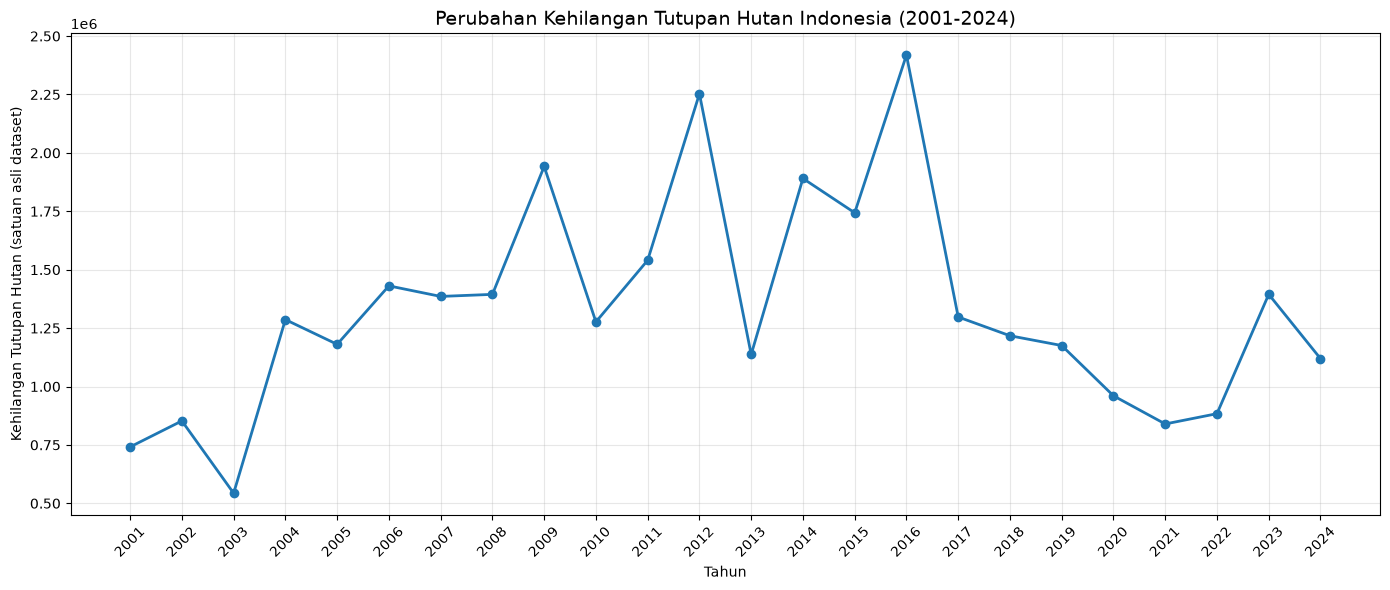


DATA YANG DIGUNAKAN DALAM GRAFIK:
Tahun 2001: 741,476.90
Tahun 2002: 852,752.50
Tahun 2003: 543,327.44
Tahun 2004: 1,286,451.90
Tahun 2005: 1,180,546.60
Tahun 2006: 1,430,826.90
Tahun 2007: 1,385,629.00
Tahun 2008: 1,394,440.10
Tahun 2009: 1,941,935.80
Tahun 2010: 1,276,621.40
Tahun 2011: 1,540,448.40
Tahun 2012: 2,253,081.50
Tahun 2013: 1,137,152.90
Tahun 2014: 1,890,665.60
Tahun 2015: 1,743,678.60
Tahun 2016: 2,419,011.20
Tahun 2017: 1,297,627.10
Tahun 2018: 1,217,328.90
Tahun 2019: 1,175,420.10
Tahun 2020: 960,275.94
Tahun 2021: 839,695.20
Tahun 2022: 883,724.90
Tahun 2023: 1,394,605.80
Tahun 2024: 1,119,481.20


In [17]:
# ==========================================
# CELL 18 - GRAFIK PERUBAHAN TAHUNAN
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    annual_table["Year"],
    annual_table["Total"],
    marker="o",
    linewidth=2
)

plt.title(
    "Perubahan Kehilangan Tutupan Hutan Indonesia (2001-2024)",
    fontsize=14
)

plt.xlabel("Tahun")
plt.ylabel("Kehilangan Tutupan Hutan (satuan asli dataset)")

plt.xticks(
    annual_table["Year"],
    rotation=45
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nDATA YANG DIGUNAKAN DALAM GRAFIK:")

for _, row in annual_table.iterrows():
    print(
        f"Tahun {int(row['Year'])}: "
        f"{row['Total']:,.2f}"
    )

In [18]:
# ==========================================
# CELL 19 - ANALISIS NILAI EKSTREM
# ==========================================

highest = annual_table.loc[
    annual_table["Total"].idxmax()
]

lowest = annual_table.loc[
    annual_table["Total"].idxmin()
]

print("=" * 60)
print("ANALISIS NILAI TERTINGGI DAN TERENDAH")
print("=" * 60)

print(
    f"Tahun kehilangan tertinggi: {int(highest['Year'])}"
)
print(
    f"Nilai kehilangan tertinggi: {highest['Total']:,.2f}"
)

print()

print(
    f"Tahun kehilangan terendah: {int(lowest['Year'])}"
)
print(
    f"Nilai kehilangan terendah: {lowest['Total']:,.2f}"
)

print("\nLima tahun dengan kehilangan tertinggi:")

display(
    annual_table.nlargest(5, "Total").to_string(index=False)
)

print("\nLima tahun dengan kehilangan terendah:")

display(
    annual_table.nsmallest(5, "Total").to_string(index=False)
)

ANALISIS NILAI TERTINGGI DAN TERENDAH
Tahun kehilangan tertinggi: 2016
Nilai kehilangan tertinggi: 2,419,011.20

Tahun kehilangan terendah: 2003
Nilai kehilangan terendah: 543,327.44

Lima tahun dengan kehilangan tertinggi:


' Year        Total\n 2016 2,419,011.20\n 2012 2,253,081.50\n 2009 1,941,935.80\n 2014 1,890,665.60\n 2015 1,743,678.60'


Lima tahun dengan kehilangan terendah:


' Year      Total\n 2003 543,327.44\n 2001 741,476.90\n 2021 839,695.20\n 2002 852,752.50\n 2022 883,724.90'

In [19]:
# ==========================================
# CELL 20 - PERUBAHAN TAHUNAN
# ==========================================

annual_table["Previous_Year"] = annual_table["Total"].shift(1)

annual_table["Absolute_Change"] = (
    annual_table["Total"] -
    annual_table["Previous_Year"]
)

annual_table["Percentage_Change"] = (
    annual_table["Absolute_Change"] /
    annual_table["Previous_Year"].replace(0, np.nan)
) * 100

print("=" * 70)
print("PERUBAHAN KEHILANGAN TUTUPAN HUTAN ANTAR TAHUN")
print("=" * 70)

display(
    annual_table[
        ["Year", "Total", "Absolute_Change", "Percentage_Change"]
    ].to_string(index=False)
)

PERUBAHAN KEHILANGAN TUTUPAN HUTAN ANTAR TAHUN


' Year        Total  Absolute_Change  Percentage_Change\n 2001   741,476.90              NaN                NaN\n 2002   852,752.50       111,275.60              15.01\n 2003   543,327.44      -309,425.06             -36.29\n 2004 1,286,451.90       743,124.46             136.77\n 2005 1,180,546.60      -105,905.30              -8.23\n 2006 1,430,826.90       250,280.30              21.20\n 2007 1,385,629.00       -45,197.90              -3.16\n 2008 1,394,440.10         8,811.10               0.64\n 2009 1,941,935.80       547,495.70              39.26\n 2010 1,276,621.40      -665,314.40             -34.26\n 2011 1,540,448.40       263,827.00              20.67\n 2012 2,253,081.50       712,633.10              46.26\n 2013 1,137,152.90    -1,115,928.60             -49.53\n 2014 1,890,665.60       753,512.70              66.26\n 2015 1,743,678.60      -146,987.00              -7.77\n 2016 2,419,011.20       675,332.60              38.73\n 2017 1,297,627.10    -1,121,384.10            

In [20]:
# ==========================================
# CELL 21 - EXPORT HASIL VALIDASI
# ==========================================

OUTPUT_DIR = "../data/processed"

os.makedirs(OUTPUT_DIR, exist_ok=True)

output_path = os.path.join(
    OUTPUT_DIR,
    "indonesia_tree_cover_loss_2001_2024.csv"
)

df_id_period[
    ["Entity", "Code", "Year", "Total"]
].to_csv(
    output_path,
    index=False
)

print("=" * 60)
print("EKSPOR DATA BERHASIL")
print("=" * 60)

print("File:", os.path.abspath(output_path))
print("Jumlah baris:", len(df_id_period))
print("Jumlah kolom:", 4)

print("\nIsi file yang diekspor:")
display(
    pd.read_csv(output_path).to_string(index=False)
)

EKSPOR DATA BERHASIL
File: d:\Semester5PS\UTS-System-Dynamics-Kehutanan\data\processed\indonesia_tree_cover_loss_2001_2024.csv
Jumlah baris: 24
Jumlah kolom: 4

Isi file yang diekspor:


'   Entity Code  Year        Total\nIndonesia  IDN  2001   741,476.90\nIndonesia  IDN  2002   852,752.50\nIndonesia  IDN  2003   543,327.44\nIndonesia  IDN  2004 1,286,451.90\nIndonesia  IDN  2005 1,180,546.60\nIndonesia  IDN  2006 1,430,826.90\nIndonesia  IDN  2007 1,385,629.00\nIndonesia  IDN  2008 1,394,440.10\nIndonesia  IDN  2009 1,941,935.80\nIndonesia  IDN  2010 1,276,621.40\nIndonesia  IDN  2011 1,540,448.40\nIndonesia  IDN  2012 2,253,081.50\nIndonesia  IDN  2013 1,137,152.90\nIndonesia  IDN  2014 1,890,665.60\nIndonesia  IDN  2015 1,743,678.60\nIndonesia  IDN  2016 2,419,011.20\nIndonesia  IDN  2017 1,297,627.10\nIndonesia  IDN  2018 1,217,328.90\nIndonesia  IDN  2019 1,175,420.10\nIndonesia  IDN  2020   960,275.94\nIndonesia  IDN  2021   839,695.20\nIndonesia  IDN  2022   883,724.90\nIndonesia  IDN  2023 1,394,605.80\nIndonesia  IDN  2024 1,119,481.20'

## 2. Pengumpulan Dataset Pendamping: Forest Area Indonesia

Dataset Tree Cover Loss digunakan untuk mengukur kehilangan tutupan pohon setiap tahun.

Untuk melengkapi informasi kondisi luas hutan, penelitian menggunakan indikator Forest Area dari World Bank yang bersumber dari FAOSTAT.

Dataset ini digunakan sebagai kandidat variabel Stock dalam perancangan model System Dynamics.

Sumber:
- World Bank: AG.LND.FRST.K2
- FAOSTAT
- Periode penelitian: 2001–2024
- Satuan asli: km²

In [22]:
# ==========================================
# CELL 23 - DOWNLOAD FOREST AREA
# ==========================================

import requests

API_URL = (
    "https://api.worldbank.org/v2/country/IDN/"
    "indicator/AG.LND.FRST.K2"
)

params = {
    "date": "2001:2024",
    "format": "json",
    "per_page": 100
}

response = requests.get(
    API_URL,
    params=params,
    timeout=30
)

print("HTTP Status:", response.status_code)
print("API URL:", response.url)

response.raise_for_status()

api_result = response.json()

if len(api_result) < 2 or api_result[1] is None:
    raise ValueError("Data Forest Area tidak ditemukan.")

print("\nMetadata API:")
print(api_result[0])

print("\nJumlah record yang diterima:", len(api_result[1]))

HTTP Status: 200
API URL: https://api.worldbank.org/v2/country/IDN/indicator/AG.LND.FRST.K2?date=2001%3A2024&format=json&per_page=100

Metadata API:
{'page': 1, 'pages': 1, 'per_page': 100, 'total': 24, 'sourceid': '2', 'lastupdated': '2026-11-11'}

Jumlah record yang diterima: 24


In [23]:
# ==========================================
# CELL 24 - MEMBENTUK DATAFRAME
# ==========================================

forest_records = []

for item in api_result[1]:

    if item["value"] is not None:

        forest_records.append({
            "Entity": item["country"]["value"],
            "Code": item["countryiso3code"],
            "Year": int(item["date"]),
            "Forest_Area_sq_km": float(item["value"])
        })

df_forest = pd.DataFrame(forest_records)

df_forest = df_forest.sort_values(
    "Year"
).reset_index(drop=True)

print("=" * 65)
print("DATA FOREST AREA INDONESIA")
print("=" * 65)

print("Jumlah baris:", len(df_forest))
print("Jumlah kolom:", len(df_forest.columns))

print("\nStruktur:")
print(df_forest.dtypes)

print("\nSeluruh data:")
print(df_forest.to_string(index=False))

DATA FOREST AREA INDONESIA
Jumlah baris: 24
Jumlah kolom: 4

Struktur:
Entity                   str
Code                     str
Year                   int64
Forest_Area_sq_km    float64
dtype: object

Seluruh data:
   Entity Code  Year  Forest_Area_sq_km
Indonesia  IDN  2001         923,932.60
Indonesia  IDN  2002         928,279.20
Indonesia  IDN  2003         932,625.80
Indonesia  IDN  2004         936,972.40
Indonesia  IDN  2005         941,319.00
Indonesia  IDN  2006         945,665.60
Indonesia  IDN  2007         950,012.20
Indonesia  IDN  2008         954,358.80
Indonesia  IDN  2009         958,705.40
Indonesia  IDN  2010         963,052.00
Indonesia  IDN  2011         960,497.40
Indonesia  IDN  2012         957,942.80
Indonesia  IDN  2013         955,388.20
Indonesia  IDN  2014         952,833.60
Indonesia  IDN  2015         950,279.00
Indonesia  IDN  2016         951,347.00
Indonesia  IDN  2017         952,415.00
Indonesia  IDN  2018         953,483.00
Indonesia  IDN  2019    

In [24]:
# ==========================================
# CELL 25 - KONVERSI SATUAN
# ==========================================

df_forest["Forest_Area_ha"] = (
    df_forest["Forest_Area_sq_km"] * 100
)

print("=" * 65)
print("KONVERSI FOREST AREA")
print("=" * 65)

print("Satuan asli   : km²")
print("Satuan konversi: hektare")

display(
    df_forest[
        ["Year", "Forest_Area_sq_km", "Forest_Area_ha"]
    ].to_string(index=False)
)

KONVERSI FOREST AREA
Satuan asli   : km²
Satuan konversi: hektare


' Year  Forest_Area_sq_km  Forest_Area_ha\n 2001         923,932.60   92,393,260.00\n 2002         928,279.20   92,827,920.00\n 2003         932,625.80   93,262,580.00\n 2004         936,972.40   93,697,240.00\n 2005         941,319.00   94,131,900.00\n 2006         945,665.60   94,566,560.00\n 2007         950,012.20   95,001,220.00\n 2008         954,358.80   95,435,880.00\n 2009         958,705.40   95,870,540.00\n 2010         963,052.00   96,305,200.00\n 2011         960,497.40   96,049,740.00\n 2012         957,942.80   95,794,280.00\n 2013         955,388.20   95,538,820.00\n 2014         952,833.60   95,283,360.00\n 2015         950,279.00   95,027,900.00\n 2016         951,347.00   95,134,700.00\n 2017         952,415.00   95,241,500.00\n 2018         953,483.00   95,348,300.00\n 2019         954,551.00   95,455,100.00\n 2020         955,619.00   95,561,900.00\n 2021         956,433.80   95,643,380.00\n 2022         957,248.60   95,724,860.00\n 2023         958,063.40   95,806

In [25]:
# ==========================================
# CELL 26 - VALIDASI FOREST AREA
# ==========================================

expected_years = set(range(2001, 2025))

actual_years = set(
    df_forest["Year"].astype(int)
)

missing_years = sorted(
    expected_years - actual_years
)

print("=" * 65)
print("VALIDASI FOREST AREA 2001-2024")
print("=" * 65)

print("Jumlah observasi:", len(df_forest))
print("Jumlah tahun unik:", df_forest["Year"].nunique())

print("Tahun awal:", df_forest["Year"].min())
print("Tahun akhir:", df_forest["Year"].max())

print("\nTahun yang hilang:")

if missing_years:
    print(missing_years)
else:
    print("Tidak ada.")

print("\nMissing values:")
print(df_forest.isnull().sum().to_string())

print("\nDuplikasi:")
print(df_forest.duplicated(["Year"]).sum())

print(
    "\nStatus:",
    "LENGKAP"
    if not missing_years and len(df_forest) == 24
    else "PERLU PEMERIKSAAN"
)

VALIDASI FOREST AREA 2001-2024
Jumlah observasi: 24
Jumlah tahun unik: 24
Tahun awal: 2001
Tahun akhir: 2024

Tahun yang hilang:
Tidak ada.

Missing values:
Entity               0
Code                 0
Year                 0
Forest_Area_sq_km    0
Forest_Area_ha       0

Duplikasi:
0

Status: LENGKAP


In [26]:
# ==========================================
# CELL 27 - PERUBAHAN FOREST AREA
# ==========================================

df_forest = df_forest.sort_values("Year").copy()

df_forest["Previous_Forest_Area"] = (
    df_forest["Forest_Area_ha"].shift(1)
)

df_forest["Net_Change_ha"] = (
    df_forest["Forest_Area_ha"] -
    df_forest["Previous_Forest_Area"]
)

df_forest["Net_Change_Percent"] = (
    df_forest["Net_Change_ha"] /
    df_forest["Previous_Forest_Area"]
) * 100

print("=" * 75)
print("PERUBAHAN LUAS HUTAN INDONESIA")
print("=" * 75)

display(
    df_forest[
        [
            "Year",
            "Forest_Area_ha",
            "Net_Change_ha",
            "Net_Change_Percent"
        ]
    ].to_string(index=False)
)

PERUBAHAN LUAS HUTAN INDONESIA


' Year  Forest_Area_ha  Net_Change_ha  Net_Change_Percent\n 2001   92,393,260.00            NaN                 NaN\n 2002   92,827,920.00     434,660.00                0.47\n 2003   93,262,580.00     434,660.00                0.47\n 2004   93,697,240.00     434,660.00                0.47\n 2005   94,131,900.00     434,660.00                0.46\n 2006   94,566,560.00     434,660.00                0.46\n 2007   95,001,220.00     434,660.00                0.46\n 2008   95,435,880.00     434,660.00                0.46\n 2009   95,870,540.00     434,660.00                0.46\n 2010   96,305,200.00     434,660.00                0.45\n 2011   96,049,740.00    -255,460.00               -0.27\n 2012   95,794,280.00    -255,460.00               -0.27\n 2013   95,538,820.00    -255,460.00               -0.27\n 2014   95,283,360.00    -255,460.00               -0.27\n 2015   95,027,900.00    -255,460.00               -0.27\n 2016   95,134,700.00     106,800.00                0.11\n 2017   95,24

Interpretasi:
- Net_Change_ha positif: luas hutan meningkat.
- Net_Change_ha negatif: luas hutan menurun.
- Net_Change_Percent: persentase perubahan terhadap tahun sebelumnya.

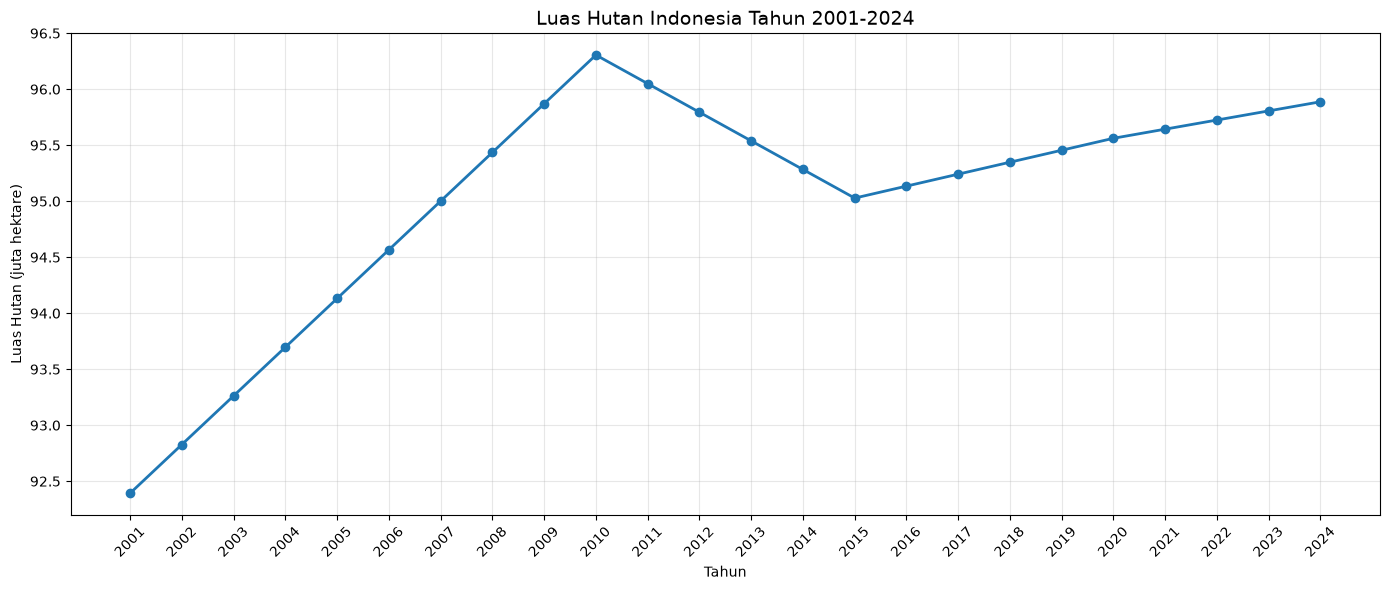


DATA GRAFIK:
2001: 92.3933 juta hektare
2002: 92.8279 juta hektare
2003: 93.2626 juta hektare
2004: 93.6972 juta hektare
2005: 94.1319 juta hektare
2006: 94.5666 juta hektare
2007: 95.0012 juta hektare
2008: 95.4359 juta hektare
2009: 95.8705 juta hektare
2010: 96.3052 juta hektare
2011: 96.0497 juta hektare
2012: 95.7943 juta hektare
2013: 95.5388 juta hektare
2014: 95.2834 juta hektare
2015: 95.0279 juta hektare
2016: 95.1347 juta hektare
2017: 95.2415 juta hektare
2018: 95.3483 juta hektare
2019: 95.4551 juta hektare
2020: 95.5619 juta hektare
2021: 95.6434 juta hektare
2022: 95.7249 juta hektare
2023: 95.8063 juta hektare
2024: 95.8878 juta hektare


In [27]:
# ==========================================
# CELL 28 - GRAFIK FOREST AREA
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    df_forest["Year"],
    df_forest["Forest_Area_ha"] / 1_000_000,
    marker="o",
    linewidth=2
)

plt.title(
    "Luas Hutan Indonesia Tahun 2001-2024",
    fontsize=14
)

plt.xlabel("Tahun")
plt.ylabel("Luas Hutan (juta hektare)")

plt.xticks(
    df_forest["Year"],
    rotation=45
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nDATA GRAFIK:")

for _, row in df_forest.iterrows():
    print(
        f"{int(row['Year'])}: "
        f"{row['Forest_Area_ha']/1_000_000:.4f} juta hektare"
    )

In [28]:
# ==========================================
# CELL 29 - EXPORT FOREST AREA
# ==========================================

OUTPUT_DIR = "../data/raw"

os.makedirs(OUTPUT_DIR, exist_ok=True)

forest_output = os.path.join(
    OUTPUT_DIR,
    "indonesia_forest_area_2001_2024.csv"
)

df_forest.to_csv(
    forest_output,
    index=False
)

print("=" * 65)
print("FOREST AREA BERHASIL DISIMPAN")
print("=" * 65)

print("File:", os.path.abspath(forest_output))
print("Jumlah data:", len(df_forest))

print("\nPreview CSV:")
print(
    pd.read_csv(forest_output).to_string(index=False)
)

FOREST AREA BERHASIL DISIMPAN
File: d:\Semester5PS\UTS-System-Dynamics-Kehutanan\data\raw\indonesia_forest_area_2001_2024.csv
Jumlah data: 24

Preview CSV:
   Entity Code  Year  Forest_Area_sq_km  Forest_Area_ha  Previous_Forest_Area  Net_Change_ha  Net_Change_Percent
Indonesia  IDN  2001         923,932.60   92,393,260.00                   NaN            NaN                 NaN
Indonesia  IDN  2002         928,279.20   92,827,920.00         92,393,260.00     434,660.00                0.47
Indonesia  IDN  2003         932,625.80   93,262,580.00         92,827,920.00     434,660.00                0.47
Indonesia  IDN  2004         936,972.40   93,697,240.00         93,262,580.00     434,660.00                0.47
Indonesia  IDN  2005         941,319.00   94,131,900.00         93,697,240.00     434,660.00                0.46
Indonesia  IDN  2006         945,665.60   94,566,560.00         94,131,900.00     434,660.00                0.46
Indonesia  IDN  2007         950,012.20   95,001,220.

# 3. Perancangan Model System Dynamics

Model yang dikembangkan berfokus pada dinamika akumulasi kehilangan tutupan pohon di Indonesia selama periode 2001–2024.

Model menggunakan pendekatan Stock and Flow dengan komponen:

1. Stock: Akumulasi Kehilangan Tutupan Pohon.
2. Inflow: Kehilangan Tutupan Pohon Tahunan.

Data historis digunakan sebagai input aliran tahunan.

Model akan menguji tiga skenario:
- Baseline: mengikuti data kehilangan tutupan pohon aktual.
- Pengurangan 10%: kehilangan tahunan dikurangi sebesar 10%.
- Pengurangan 20%: kehilangan tahunan dikurangi sebesar 20%.

Akumulasi kehilangan dihitung menggunakan penjumlahan aliran tahunan.

In [36]:
# ==========================================
# CELL 31 - VARIABEL MODEL
# ==========================================

# Variabel waktu
START_YEAR = 2001
END_YEAR = 2024

# Kondisi awal stock
INITIAL_STOCK = 0.0

# Parameter skenario
SCENARIOS = {
    "Baseline": 0.00,
    "Pengurangan 10%": 0.10,
    "Pengurangan 20%": 0.20
}

# Nama variabel
STOCK_NAME = "Akumulasi Kehilangan Tutupan Pohon"
FLOW_NAME = "Kehilangan Tutupan Pohon Tahunan"

print("=" * 65)
print("KONFIGURASI MODEL SYSTEM DYNAMICS")
print("=" * 65)

print("Periode simulasi:", START_YEAR, "-", END_YEAR)
print("Stock awal:", INITIAL_STOCK, "hektare")
print("Stock:", STOCK_NAME)
print("Inflow:", FLOW_NAME)

print("\nSkenario simulasi:")

for scenario, reduction in SCENARIOS.items():
    print(f"{scenario}: pengurangan {reduction * 100:.0f}%")

KONFIGURASI MODEL SYSTEM DYNAMICS
Periode simulasi: 2001 - 2024
Stock awal: 0.0 hektare
Stock: Akumulasi Kehilangan Tutupan Pohon
Inflow: Kehilangan Tutupan Pohon Tahunan

Skenario simulasi:
Baseline: pengurangan 0%
Pengurangan 10%: pengurangan 10%
Pengurangan 20%: pengurangan 20%


In [37]:
# ==========================================
# CELL 32 - PERSIAPAN DATA SIMULASI
# ==========================================

df_model = df_id_period[
    ["Year", "Total"]
].copy()

df_model = df_model.sort_values(
    "Year"
).reset_index(drop=True)

df_model["Year"] = df_model["Year"].astype(int)
df_model["Total"] = df_model["Total"].astype(float)

# Pemeriksaan data
assert len(df_model) == 24
assert df_model["Year"].min() == START_YEAR
assert df_model["Year"].max() == END_YEAR
assert df_model["Year"].is_unique
assert df_model["Total"].notna().all()
assert (df_model["Total"] >= 0).all()

print("=" * 65)
print("DATA INPUT MODEL")
print("=" * 65)

print("Jumlah observasi:", len(df_model))
print("Tahun awal:", df_model["Year"].min())
print("Tahun akhir:", df_model["Year"].max())

print("\nData input:")

print(
    df_model.to_string(
        index=False,
        formatters={"Total": "{:,.2f}".format}
    )
)

print("\nValidasi input: BERHASIL")

DATA INPUT MODEL
Jumlah observasi: 24
Tahun awal: 2001
Tahun akhir: 2024

Data input:
 Year        Total
 2001   741,476.90
 2002   852,752.50
 2003   543,327.44
 2004 1,286,451.90
 2005 1,180,546.60
 2006 1,430,826.90
 2007 1,385,629.00
 2008 1,394,440.10
 2009 1,941,935.80
 2010 1,276,621.40
 2011 1,540,448.40
 2012 2,253,081.50
 2013 1,137,152.90
 2014 1,890,665.60
 2015 1,743,678.60
 2016 2,419,011.20
 2017 1,297,627.10
 2018 1,217,328.90
 2019 1,175,420.10
 2020   960,275.94
 2021   839,695.20
 2022   883,724.90
 2023 1,394,605.80
 2024 1,119,481.20

Validasi input: BERHASIL




Persamaan:
\[
Stock(t)=Stock(t-1)+Flow(t)
\]

Aliran tahunan untuk setiap skenario:
\[
Flow(t)=DataHistoris(t)\times(1-r)
\]

Keterangan:
- \(r\) adalah tingkat pengurangan kehilangan.
- Stock awal ditetapkan sebesar nol.
- Setiap tahun, aliran kehilangan ditambahkan ke stock.

In [38]:
# ==========================================
# CELL 33 - FUNGSI SIMULASI
# ==========================================

def simulate_system_dynamics(
    data,
    reduction_rate=0.0,
    initial_stock=0.0
):

    results = []

    current_stock = initial_stock

    for _, row in data.iterrows():

        year = int(row["Year"])

        historical_loss = float(row["Total"])

        # Menghitung inflow berdasarkan skenario
        annual_flow = (
            historical_loss * (1 - reduction_rate)
        )

        # Menghitung akumulasi stock
        current_stock = current_stock + annual_flow

        results.append({
            "Year": year,
            "Historical_Loss": historical_loss,
            "Annual_Flow": annual_flow,
            "Accumulated_Loss": current_stock
        })

    return pd.DataFrame(results)


print("Fungsi simulasi berhasil dibuat.")

print("\nPersamaan model:")
print("Annual Flow = Historical Loss × (1 - Reduction Rate)")
print("Stock(t) = Stock(t-1) + Annual Flow(t)")

Fungsi simulasi berhasil dibuat.

Persamaan model:
Annual Flow = Historical Loss × (1 - Reduction Rate)
Stock(t) = Stock(t-1) + Annual Flow(t)


In [39]:
# ==========================================
# CELL 34 - SIMULASI SELURUH SKENARIO
# ==========================================

simulation_results = {}

for scenario, reduction in SCENARIOS.items():

    simulation_results[scenario] = simulate_system_dynamics(
        data=df_model,
        reduction_rate=reduction,
        initial_stock=INITIAL_STOCK
    )

    print(
        f"Simulasi {scenario}: "
        f"{len(simulation_results[scenario])} observasi"
    )

print("\nSeluruh simulasi berhasil dijalankan.")

Simulasi Baseline: 24 observasi
Simulasi Pengurangan 10%: 24 observasi
Simulasi Pengurangan 20%: 24 observasi

Seluruh simulasi berhasil dijalankan.


In [40]:
# ==========================================
# CELL 35 - TABEL HASIL SIMULASI
# ==========================================

df_comparison = pd.DataFrame({
    "Year": df_model["Year"],
    "Baseline": simulation_results["Baseline"]["Accumulated_Loss"],
    "Pengurangan_10": simulation_results["Pengurangan 10%"]["Accumulated_Loss"],
    "Pengurangan_20": simulation_results["Pengurangan 20%"]["Accumulated_Loss"]
})

print("=" * 90)
print("PERBANDINGAN AKUMULASI KEHILANGAN TUTUPAN POHON")
print("=" * 90)

print(
    df_comparison.to_string(
        index=False,
        formatters={
            col: "{:,.2f}".format
            for col in df_comparison.columns
            if col != "Year"
        }
    )
)

PERBANDINGAN AKUMULASI KEHILANGAN TUTUPAN POHON
 Year      Baseline Pengurangan_10 Pengurangan_20
 2001    741,476.90     667,329.21     593,181.52
 2002  1,594,229.40   1,434,806.46   1,275,383.52
 2003  2,137,556.84   1,923,801.16   1,710,045.47
 2004  3,424,008.74   3,081,607.87   2,739,206.99
 2005  4,604,555.34   4,144,099.81   3,683,644.27
 2006  6,035,382.24   5,431,844.02   4,828,305.79
 2007  7,421,011.24   6,678,910.12   5,936,808.99
 2008  8,815,451.34   7,933,906.21   7,052,361.07
 2009 10,757,387.14   9,681,648.43   8,605,909.71
 2010 12,034,008.54  10,830,607.69   9,627,206.83
 2011 13,574,456.94  12,217,011.25  10,859,565.55
 2012 15,827,538.44  14,244,784.60  12,662,030.75
 2013 16,964,691.34  15,268,222.21  13,571,753.07
 2014 18,855,356.94  16,969,821.25  15,084,285.55
 2015 20,599,035.54  18,539,131.99  16,479,228.43
 2016 23,018,046.74  20,716,242.07  18,414,437.39
 2017 24,315,673.84  21,884,106.46  19,452,539.07
 2018 25,533,002.74  22,979,702.47  20,426,402.19
 2

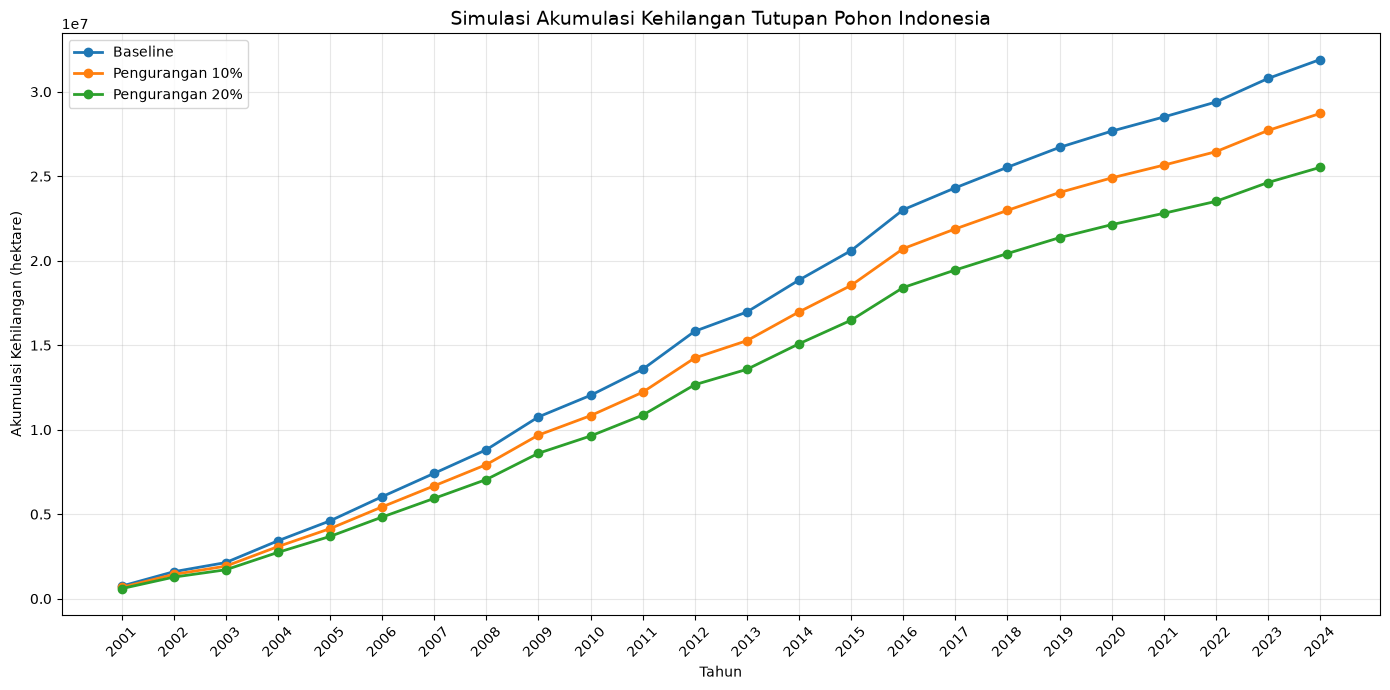

DATA GRAFIK PERBANDINGAN SKENARIO

Baseline
Tahun 2001: 741,476.90 hektare
Tahun 2002: 1,594,229.40 hektare
Tahun 2003: 2,137,556.84 hektare
Tahun 2004: 3,424,008.74 hektare
Tahun 2005: 4,604,555.34 hektare
Tahun 2006: 6,035,382.24 hektare
Tahun 2007: 7,421,011.24 hektare
Tahun 2008: 8,815,451.34 hektare
Tahun 2009: 10,757,387.14 hektare
Tahun 2010: 12,034,008.54 hektare
Tahun 2011: 13,574,456.94 hektare
Tahun 2012: 15,827,538.44 hektare
Tahun 2013: 16,964,691.34 hektare
Tahun 2014: 18,855,356.94 hektare
Tahun 2015: 20,599,035.54 hektare
Tahun 2016: 23,018,046.74 hektare
Tahun 2017: 24,315,673.84 hektare
Tahun 2018: 25,533,002.74 hektare
Tahun 2019: 26,708,422.84 hektare
Tahun 2020: 27,668,698.78 hektare
Tahun 2021: 28,508,393.98 hektare
Tahun 2022: 29,392,118.88 hektare
Tahun 2023: 30,786,724.68 hektare
Tahun 2024: 31,906,205.88 hektare

Pengurangan 10%
Tahun 2001: 667,329.21 hektare
Tahun 2002: 1,434,806.46 hektare
Tahun 2003: 1,923,801.16 hektare
Tahun 2004: 3,081,607.87 hektare
Tah

In [41]:
# ==========================================
# CELL 36 - GRAFIK PERBANDINGAN SKENARIO
# ==========================================

plt.figure(figsize=(14, 7))

for scenario, result in simulation_results.items():

    plt.plot(
        result["Year"],
        result["Accumulated_Loss"],
        marker="o",
        linewidth=2,
        label=scenario
    )

plt.title(
    "Simulasi Akumulasi Kehilangan Tutupan Pohon Indonesia",
    fontsize=14
)

plt.xlabel("Tahun")
plt.ylabel("Akumulasi Kehilangan (hektare)")

plt.xticks(df_model["Year"], rotation=45)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("=" * 75)
print("DATA GRAFIK PERBANDINGAN SKENARIO")
print("=" * 75)

for scenario, result in simulation_results.items():

    print(f"\n{scenario}")

    for _, row in result.iterrows():

        print(
            f"Tahun {int(row['Year'])}: "
            f"{row['Accumulated_Loss']:,.2f} hektare"
        )

In [42]:
# ==========================================
# CELL 37 - EVALUASI SKENARIO
# ==========================================

baseline_final = (
    simulation_results["Baseline"]["Accumulated_Loss"].iloc[-1]
)

evaluation = []

for scenario, result in simulation_results.items():

    final_stock = result["Accumulated_Loss"].iloc[-1]

    difference = baseline_final - final_stock

    reduction_percentage = (
        difference / baseline_final
    ) * 100

    evaluation.append({
        "Scenario": scenario,
        "Final_Accumulation": final_stock,
        "Difference_From_Baseline": difference,
        "Reduction_Percentage": reduction_percentage
    })

df_evaluation = pd.DataFrame(evaluation)

print("=" * 90)
print("EVALUASI HASIL SIMULASI")
print("=" * 90)

print(
    df_evaluation.to_string(
        index=False,
        formatters={
            "Final_Accumulation": "{:,.2f}".format,
            "Difference_From_Baseline": "{:,.2f}".format,
            "Reduction_Percentage": "{:.2f}%".format
        }
    )
)

print("\nINTERPRETASI AKHIR")

for _, row in df_evaluation.iterrows():

    print(
        f"{row['Scenario']}: "
        f"akumulasi {row['Final_Accumulation']:,.2f} hektare."
    )

EVALUASI HASIL SIMULASI
       Scenario Final_Accumulation Difference_From_Baseline Reduction_Percentage
       Baseline      31,906,205.88                     0.00                0.00%
Pengurangan 10%      28,715,585.29             3,190,620.59               10.00%
Pengurangan 20%      25,524,964.70             6,381,241.18               20.00%

INTERPRETASI AKHIR
Baseline: akumulasi 31,906,205.88 hektare.
Pengurangan 10%: akumulasi 28,715,585.29 hektare.
Pengurangan 20%: akumulasi 25,524,964.70 hektare.


In [43]:
# ==========================================
# CELL 38 - EXPORT HASIL SIMULASI
# ==========================================

OUTPUT_DIR = "../data/processed"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Export tabel perbandingan
comparison_path = os.path.join(
    OUTPUT_DIR,
    "simulation_scenario_comparison.csv"
)

df_comparison.to_csv(
    comparison_path,
    index=False
)

# Export evaluasi
evaluation_path = os.path.join(
    OUTPUT_DIR,
    "simulation_scenario_evaluation.csv"
)

df_evaluation.to_csv(
    evaluation_path,
    index=False
)

# Export hasil detail setiap skenario
for scenario, result in simulation_results.items():

    filename = (
        scenario.lower()
        .replace(" ", "_")
        .replace("%", "percent")
        + ".csv"
    )

    result.to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=False
    )

print("=" * 65)
print("EXPORT HASIL SIMULASI BERHASIL")
print("=" * 65)

print("1.", os.path.abspath(comparison_path))
print("2.", os.path.abspath(evaluation_path))

print("\nJumlah skenario:", len(simulation_results))
print("Periode:", START_YEAR, "-", END_YEAR)

EXPORT HASIL SIMULASI BERHASIL
1. d:\Semester5PS\UTS-System-Dynamics-Kehutanan\data\processed\simulation_scenario_comparison.csv
2. d:\Semester5PS\UTS-System-Dynamics-Kehutanan\data\processed\simulation_scenario_evaluation.csv

Jumlah skenario: 3
Periode: 2001 - 2024


# 4. Verifikasi Model dan Analisis Hasil

Verifikasi dilakukan untuk memastikan bahwa model menjalankan perhitungan sesuai dengan rancangan stock-flow. Pemeriksaan meliputi kesesuaian total akumulasi dengan jumlah kehilangan tutupan pohon tahunan, konsistensi pengurangan skenario, dan kenaikan nilai akumulasi setiap tahun.

In [44]:
# VERIFIKASI MODEL

baseline = simulation_results["Baseline"]
scenario_10 = simulation_results["Pengurangan 10%"]
scenario_20 = simulation_results["Pengurangan 20%"]

# 1. Akumulasi akhir harus sama dengan total data historis
assert abs(
    baseline["Accumulated_Loss"].iloc[-1] - df_model["Total"].sum()
) < 0.01

# 2. Akumulasi harus terus meningkat
assert baseline["Accumulated_Loss"].is_monotonic_increasing
assert scenario_10["Accumulated_Loss"].is_monotonic_increasing
assert scenario_20["Accumulated_Loss"].is_monotonic_increasing

# 3. Skenario pengurangan harus lebih rendah dari baseline
assert (
    scenario_10["Accumulated_Loss"].iloc[-1]
    < baseline["Accumulated_Loss"].iloc[-1]
)

assert (
    scenario_20["Accumulated_Loss"].iloc[-1]
    < scenario_10["Accumulated_Loss"].iloc[-1]
)

# 4. Persentase pengurangan harus sesuai skenario
assert abs(
    scenario_10["Accumulated_Loss"].iloc[-1]
    / baseline["Accumulated_Loss"].iloc[-1] - 0.90
) < 0.000001

assert abs(
    scenario_20["Accumulated_Loss"].iloc[-1]
    / baseline["Accumulated_Loss"].iloc[-1] - 0.80
) < 0.000001

print("=" * 75)
print("HASIL VERIFIKASI MODEL")
print("=" * 75)
print("Total data historis sesuai dengan akumulasi baseline : LULUS")
print("Akumulasi meningkat setiap tahun                    : LULUS")
print("Skenario pengurangan 10% lebih rendah dari baseline : LULUS")
print("Skenario pengurangan 20% lebih rendah dari 10%       : LULUS")
print("Persentase pengurangan sesuai rancangan              : LULUS")
print("\nKESIMPULAN: Seluruh pemeriksaan verifikasi berhasil.")

HASIL VERIFIKASI MODEL
Total data historis sesuai dengan akumulasi baseline : LULUS
Akumulasi meningkat setiap tahun                    : LULUS
Skenario pengurangan 10% lebih rendah dari baseline : LULUS
Skenario pengurangan 20% lebih rendah dari 10%       : LULUS
Persentase pengurangan sesuai rancangan              : LULUS

KESIMPULAN: Seluruh pemeriksaan verifikasi berhasil.


In [45]:
# ANALISIS DAMPAK SKENARIO

final_baseline = baseline["Accumulated_Loss"].iloc[-1]
final_10 = scenario_10["Accumulated_Loss"].iloc[-1]
final_20 = scenario_20["Accumulated_Loss"].iloc[-1]

difference_10 = final_baseline - final_10
difference_20 = final_baseline - final_20

print("=" * 75)
print("ANALISIS DAMPAK SKENARIO PENGURANGAN")
print("=" * 75)

print(f"Total akumulasi baseline       : {final_baseline:,.2f} hektare")
print(f"Pengurangan melalui skenario 10%: {difference_10:,.2f} hektare")
print(f"Pengurangan melalui skenario 20%: {difference_20:,.2f} hektare")

print("\nPERBANDINGAN ANTAR-SKENARIO")
print(f"Tambahan pengurangan dari 10% ke 20%: {difference_20 - difference_10:,.2f} hektare")

print("\nINTERPRETASI:")
print(
    f"Skenario pengurangan 10% menghasilkan akumulasi "
    f"{difference_10:,.2f} hektare lebih rendah daripada baseline."
)
print(
    f"Skenario pengurangan 20% menghasilkan akumulasi "
    f"{difference_20:,.2f} hektare lebih rendah daripada baseline."
)

ANALISIS DAMPAK SKENARIO PENGURANGAN
Total akumulasi baseline       : 31,906,205.88 hektare
Pengurangan melalui skenario 10%: 3,190,620.59 hektare
Pengurangan melalui skenario 20%: 6,381,241.18 hektare

PERBANDINGAN ANTAR-SKENARIO
Tambahan pengurangan dari 10% ke 20%: 3,190,620.59 hektare

INTERPRETASI:
Skenario pengurangan 10% menghasilkan akumulasi 3,190,620.59 hektare lebih rendah daripada baseline.
Skenario pengurangan 20% menghasilkan akumulasi 6,381,241.18 hektare lebih rendah daripada baseline.


## 4.1 Interpretasi Hasil Simulasi

Hasil simulasi menunjukkan bahwa besarnya pengurangan kehilangan tutupan pohon tahunan berpengaruh langsung terhadap akumulasi kehilangan tutupan pohon selama periode 2001–2024.

Pada skenario baseline, akumulasi mencapai 31.906.205,88 hektare. Ketika kehilangan tutupan pohon tahunan diasumsikan berkurang sebesar 10%, akumulasi menjadi 28.715.585,29 hektare. Sementara itu, pengurangan sebesar 20% menghasilkan akumulasi sebesar 25.524.964,70 hektare.

Hasil tersebut memperlihatkan bahwa semakin besar pengurangan kehilangan tutupan pohon tahunan, semakin rendah akumulasi kehilangan yang dihasilkan model.

## 4.2 Batasan Model

Model ini memiliki beberapa batasan:

1. Model hanya menggunakan satu variabel stock dan satu variabel flow.
2. Data yang digunakan merupakan data historis kehilangan tutupan pohon Indonesia tahun 2001–2024.
3. Skenario pengurangan 10% dan 20% merupakan asumsi simulasi, bukan hasil kebijakan yang benar-benar terjadi.
4. Model belum memasukkan faktor lain seperti reforestasi, kebakaran hutan, perubahan penggunaan lahan, dan aktivitas manusia.
5. Akumulasi yang dihitung merupakan akumulasi kehilangan tutupan pohon selama periode simulasi, bukan luas hutan Indonesia yang tersisa.

Dengan demikian, model digunakan untuk memperlihatkan konsep akumulasi stock-flow dan membandingkan beberapa skenario pengurangan, bukan untuk menghitung luas hutan tersisa atau menghasilkan prediksi kondisi hutan secara menyeluruh.